<a href="https://colab.research.google.com/github/kenneth-003/Kiwanukakenneth/blob/main/Competition_GCI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kaggle


In [2]:

from google.colab import files

uploaded = files.upload()


Saving kaggle (1).json to kaggle (1).json


In [3]:
import os

# Configure Kaggle credentials
!mkdir -p ~/.kaggle
!cp 'kaggle (1).json' ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

# Verify configuration
if os.path.exists(os.path.expanduser('~/.kaggle/kaggle.json')):
    print('Kaggle API key is successfully configured!')
else:
    print('Kaggle API configuration failed.')

Kaggle API key is successfully configured!


In [4]:
# Create directory and download the competition dataset
!mkdir -p home-credit-default-risk
!kaggle competitions download -c home-credit-default-risk -p home-credit-default-risk

# Unzip the downloaded dataset
import zipfile
import glob

for zip_file in glob.glob('home-credit-default-risk/*.zip'):
    print(f'Extracting {zip_file}...')
    with zipfile.ZipFile(zip_file, 'r') as zip_ref:
        zip_ref.extractall('home-credit-default-risk')
    os.remove(zip_file)

print('Dataset successfully downloaded and extracted into "home-credit-default-risk" folder!')

100% 688M/688M [00:04<00:00, 172MB/s]

Extracting home-credit-default-risk/home-credit-default-risk.zip...
Dataset successfully downloaded and extracted into "home-credit-default-risk" folder!


In [5]:
# Download the Home Credit Default Risk competition dataset
!kaggle competitions download -c home-credit-default-risk

# Create a directory and unzip the downloaded dataset
import zipfile
import os

100% 688M/688M [00:04<00:00, 154MB/s] 



In [6]:
import os, re, gc, glob, json, time, hashlib, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve, log_loss
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
PALETTE = {0: '#4C72B0', 1: '#C44E52'}

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PATH = '/content/drive/MyDrive/competition'
except ImportError:
    PATH = './competition'

# Fallback to local directory if Google Drive path is missing
if not os.path.exists(PATH):
    if os.path.exists('home-credit-default-risk'):
        PATH = 'home-credit-default-risk'
    else:
        PATH = '.'

# ----------------------------- CONFIG: edit here only -----------------------------
SEED           = 42
N_FOLDS        = 5
METRIC         = 'auc'
QUICK          = False
USE_AUX_TABLES = True
RESUME         = True
SPEED          = 'fast'
SPEED_S7       = 'fast'

PROFILE = {
    'fast': dict(optuna_trials=15, optuna_timeout=600,  n_seeds=1, patience=50,  max_bin=63,  tune_lr=0.10,
                 final_lr=0.05, sel_folds=3, sel_fracs=(0.4,), col_sel=0.4,
                 patience7=50, xgb_lr=0.10, xgb_trees=1500, xgb_bins=64,  cat_lr=0.10, cat_iters=1500, cat_borders=64),
    'full': dict(optuna_trials=40, optuna_timeout=1500, n_seeds=3, patience=150, max_bin=255, tune_lr=0.05,
                 final_lr=0.02, sel_folds=N_FOLDS, sel_fracs=(0.7, 0.4), col_sel=0.6,
                 patience7=150, xgb_lr=0.03, xgb_trees=5000, xgb_bins=256, cat_lr=0.05, cat_iters=4000, cat_borders=254),
}
assert SPEED in PROFILE and SPEED_S7 in PROFILE, "SPEED and SPEED_S7 must be 'fast' or 'full'"
P = PROFILE[SPEED]
OPTUNA_TRIALS  = 5 if QUICK else P['optuna_trials']
OPTUNA_TIMEOUT = 60 if QUICK else P['optuna_timeout']
N_SEEDS_LGB    = 1 if QUICK else P['n_seeds']
MAX_TREES      = 60 if QUICK else 10000
PATIENCE       = 20 if QUICK else P['patience']
MAX_BIN        = P['max_bin']
TUNE_LR        = 0.10 if QUICK else P['tune_lr']
FINAL_LR       = 0.10 if QUICK else P['final_lr']
SEL_FOLDS      = min(P['sel_folds'], N_FOLDS)
SEL_FRACS      = P['sel_fracs']
FORCE_REBUILD  = False
FE_VERSION     = 'v1'
EXPECTED_TEST_ROWS = None
TRAIN_FILE, TEST_FILE, SAMPLE_FILE = None, None, None
# -----------------------------------------------------------------------------------

METRICS = {
    'auc':     dict(score=lambda y, p: roc_auc_score(y, p), lgb='auc', xgb='auc', cat='AUC', label='ROC AUC'),
    'logloss': dict(score=lambda y, p: -log_loss(y, np.clip(p, 1e-15, 1 - 1e-15)), lgb='binary_logloss',
                    xgb='logloss', cat='Logloss', label='negative log loss'),
}
assert METRIC in METRICS, f'METRIC must be one of {list(METRICS)}'
M = METRICS[METRIC]
score_fn = M['score']

assert os.path.isdir(PATH), (
    f'PATH not found: {PATH}\nIn the Colab file browser find the "competition" folder under '
    'drive/MyDrive, right-click -> Copy path, and paste it into PATH.')
if os.path.isdir('/content/drive/MyDrive'):
    OUT_DIR = '/content/drive/MyDrive/competition_output'
else:
    OUT_DIR = os.path.join(PATH, 'output')
ART_DIR = os.path.join(OUT_DIR, 'artifacts')
os.makedirs(ART_DIR, exist_ok=True)

# ---- experiment log: one row per experiment, used for the results table and charts ----
EXPERIMENTS = []
def log_exp(name, scores, n_features, seconds, note=''):
    EXPERIMENTS.append(dict(experiment=name, n_features=n_features, score=float(np.mean(scores)),
                            std=float(np.std(scores)), seconds=round(seconds), note=note))
    print(f'[{name}] {M["label"]}: {np.mean(scores):.5f} (+/- {np.std(scores):.5f})  '
          f'{n_features} features  {seconds:.0f}s {note}')

print(f'Metric: {M["label"]} | folds={N_FOLDS} | seed={SEED} | QUICK={QUICK} | PATH={PATH}')
RESTORED = False

Mounted at /content/drive
Metric: ROC AUC | folds=5 | seed=42 | QUICK=False | PATH=home-credit-default-risk


### Restore point
After Section 3 the notebook saves a checkpoint of the finished features. If Colab restarts or disconnects, run **Setup** and **this cell**, and Sections 1-3 are skipped automatically.

In [7]:

import pickle

def data_signature():
    files = sorted(f for f in glob.glob(f'{PATH}/**/*.csv', recursive=True)
                   if os.sep + 'output' + os.sep not in f)
    items = [(os.path.relpath(f, PATH), os.path.getsize(f), int(os.path.getmtime(f))) for f in files]
    return hashlib.md5(json.dumps([items, USE_AUX_TABLES, FE_VERSION]).encode()).hexdigest()

CKPT = os.path.join(ART_DIR, 'features_checkpoint.pkl')
SIGNATURE = data_signature()
if RESUME and not FORCE_REBUILD and os.path.exists(CKPT):
    with open(CKPT, 'rb') as fh:
        ckpt = pickle.load(fh)
    if ckpt.get('signature') == SIGNATURE:
        globals().update(ckpt['state'])
        RESTORED = True
        print(f"Restored features from checkpoint: train {X.shape}, test {Xt.shape}, {len(features)} features.")
        print("Sections 1-3 will be skipped. Continue with Section 4.")
    else:
        print('Checkpoint is out of date (data, aux-table setting or FE_VERSION changed): rebuilding features.')
    del ckpt
else:
    print('No checkpoint to restore: running Sections 1-3 normally.')

No checkpoint to restore: running Sections 1-3 normally.


## 1. Load data and validate

In [8]:
if not RESTORED:
    # Update PATH to find the downloaded dataset
    if os.path.exists('home-credit-default-risk'):
        PATH = 'home-credit-default-risk'

    csvs = sorted(f for f in glob.glob(f'{PATH}/**/*.csv', recursive=True)
                  if os.sep + 'output' + os.sep not in f)
    print(f'CSV files under {PATH}:')
    for f in csvs:
        print(f'  {os.path.getsize(f)/1e6:9.1f} MB  {os.path.relpath(f, PATH)}')
    assert csvs, 'No CSV files found. Check PATH and that the folder was unzipped before uploading.'

    def pick(override, keywords, exclude=()):
        if override:
            return next(f for f in csvs if os.path.basename(f) == override)
        cands = [f for f in csvs if any(k in os.path.basename(f).lower() for k in keywords)
                 and not any(k in os.path.basename(f).lower() for k in exclude)]
        assert cands, f'No file matching {keywords}. Set it manually in the config cell.'
        if len(cands) > 1:
            print(f'  note: several matches for {keywords}: {[os.path.basename(c) for c in cands]}'
                  f' -> using {os.path.basename(cands[0])}')
        return cands[0]

    sample_path = pick(SAMPLE_FILE, ['sample', 'submission'])
    train_path  = pick(TRAIN_FILE,  ['train'], exclude=['sample', 'submission'])
    test_path   = pick(TEST_FILE,   ['test'],  exclude=['sample', 'submission'])
    print('\ntrain :', os.path.relpath(train_path, PATH))
    print('test  :', os.path.relpath(test_path, PATH))
    print('sample:', os.path.relpath(sample_path, PATH))

    train  = pd.read_csv(train_path)
    test   = pd.read_csv(test_path)
    sample = pd.read_csv(sample_path)
    print(f'DATA SOURCE: {PATH}  |  train rows={len(train):,}  test rows={len(test):,}  sample_submission rows={len(sample):,}')
    if EXPECTED_TEST_ROWS is not None:
        assert len(sample) == EXPECTED_TEST_ROWS, (
            f'sample_submission has {len(sample):,} rows but the competition expects {EXPECTED_TEST_ROWS:,}. '
            'You are probably using the wrong data (for example the public Kaggle files). Check README.ipynb.')

    ID_COL, TARGET = sample.columns[0], sample.columns[1]
    assert ID_COL in train.columns and ID_COL in test.columns and TARGET in train.columns, (
        f'Inferred ID={ID_COL} / TARGET={TARGET} not found in train/test. '
        f'Train columns start with: {list(train.columns[:5])}')
    assert TARGET not in test.columns, 'Target column found in test; wrong file picked?'
    assert train[ID_COL].is_unique and test[ID_COL].is_unique, 'Duplicate IDs found.'
    assert set(sample[ID_COL]) == set(test[ID_COL]), 'Sample submission IDs differ from test IDs.'

    print(f'\nID={ID_COL}  TARGET={TARGET}  train={train.shape}  test={test.shape}')
    print('Default rate:', round(train[TARGET].mean(), 4))
    raw_feature_names = [c for c in train.columns if c not in (ID_COL, TARGET)]

    only_train = set(train.columns) - set(test.columns) - {TARGET}
    only_test  = set(test.columns) - set(train.columns)
    print('Columns only in train (besides target):', sorted(only_train) or 'none')
    print('Columns only in test:', sorted(only_test) or 'none')
    aux_files = [f for f in csvs if f not in {train_path, test_path, sample_path}]
    print('Other tables:', [os.path.relpath(f, PATH) for f in aux_files] or 'none')

CSV files under home-credit-default-risk:
        0.0 MB  HomeCredit_columns_description.csv
      392.7 MB  POS_CASH_balance.csv
       26.6 MB  application_test.csv
      166.1 MB  application_train.csv
      170.0 MB  bureau.csv
      375.6 MB  bureau_balance.csv
      424.6 MB  credit_card_balance.csv
      723.1 MB  installments_payments.csv
      405.0 MB  previous_application.csv
        0.5 MB  sample_submission.csv

train : application_train.csv
test  : application_test.csv
sample: sample_submission.csv
DATA SOURCE: home-credit-default-risk  |  train rows=307,511  test rows=48,744  sample_submission rows=48,744

ID=SK_ID_CURR  TARGET=TARGET  train=(307511, 122)  test=(48744, 121)
Default rate: 0.0807
Columns only in train (besides target): none
Columns only in test: none
Other tables: ['HomeCredit_columns_description.csv', 'POS_CASH_balance.csv', 'bureau.csv', 'bureau_balance.csv', 'credit_card_balance.csv', 'installments_payments.csv', 'previous_application.csv']


## 2. Explore the data
The slides recommend visualizing the data before adding features. What to look for:
- **Class balance:** a rare positive class is why AUC (a ranking metric) is typical here.
- **Missing values:** in tree models, "is missing" is often itself informative, so we keep NaNs rather than imputing.
- **Decile plots:** a clear monotonic trend means the feature carries signal; the dashed line is the overall default rate.

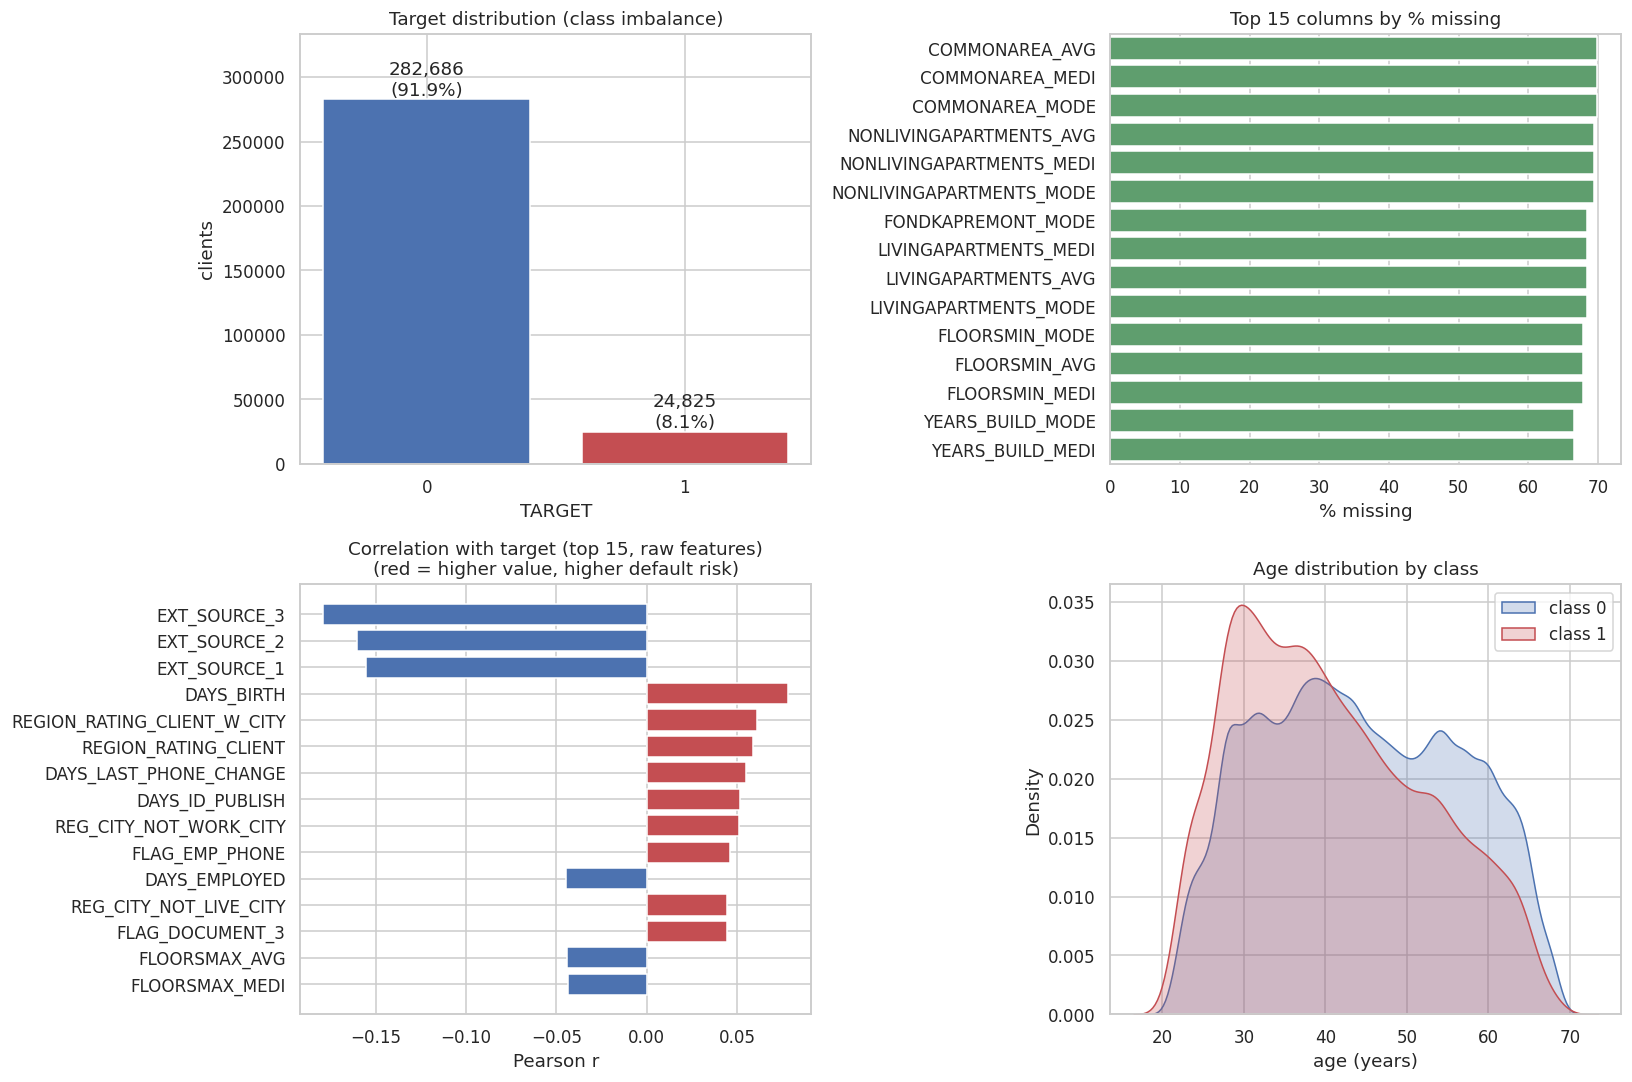

In [9]:
if not RESTORED:
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # (a) class balance
    vc = train[TARGET].value_counts().sort_index()
    ax = axes[0, 0]
    bars = ax.bar(vc.index.astype(str), vc.values, color=[PALETTE.get(i, 'grey') for i in vc.index])
    for b, v in zip(bars, vc.values):
        ax.text(b.get_x() + b.get_width() / 2, v, f'{v:,}\n({v/len(train):.1%})', ha='center', va='bottom')
    ax.set_ylim(0, vc.max() * 1.18)
    ax.set_title('Target distribution (class imbalance)'); ax.set_xlabel(TARGET); ax.set_ylabel('clients')

    # (b) missing values
    miss = (train.drop(columns=[TARGET]).isna().mean() * 100).sort_values(ascending=False)
    miss = miss[miss > 0].head(15)
    if len(miss):
        sns.barplot(x=miss.values, y=miss.index, color='#55A868', ax=axes[0, 1])
        axes[0, 1].set_title(f'Top {len(miss)} columns by % missing'); axes[0, 1].set_xlabel('% missing'); axes[0, 1].set_ylabel('')
    else:
        axes[0, 1].text(0.5, 0.5, 'No missing values', ha='center'); axes[0, 1].axis('off')

    # (c) correlation of numeric columns with the target
    num = train.select_dtypes('number').drop(columns=[ID_COL, TARGET], errors='ignore')
    corr = num.corrwith(train[TARGET]).dropna()
    top = corr.reindex(corr.abs().sort_values(ascending=False).head(15).index)
    axes[1, 0].barh(top.index[::-1], top.values[::-1], color=['#C44E52' if v > 0 else '#4C72B0' for v in top.values[::-1]])
    axes[1, 0].set_title('Correlation with target (top 15, raw features)\n(red = higher value, higher default risk)'); axes[1, 0].set_xlabel('Pearson r')

    # (d) age (or the strongest numeric feature) by class
    ax = axes[1, 1]
    if 'DAYS_BIRTH' in train:
        age = -train['DAYS_BIRTH'] / 365.25
        for k in sorted(train[TARGET].unique()):
            sns.kdeplot(age[train[TARGET] == k], ax=ax, color=PALETTE.get(k), label=f'class {k}', fill=True, alpha=.25)
        ax.set_title('Age distribution by class'); ax.set_xlabel('age (years)')
    else:
        c0 = top.index[0]
        for k in sorted(train[TARGET].unique()):
            sns.kdeplot(train.loc[train[TARGET] == k, c0].dropna(), ax=ax, color=PALETTE.get(k), label=f'class {k}', fill=True, alpha=.25)
        ax.set_title(f'{c0} by class')
    ax.legend()
    plt.tight_layout(); plt.show()

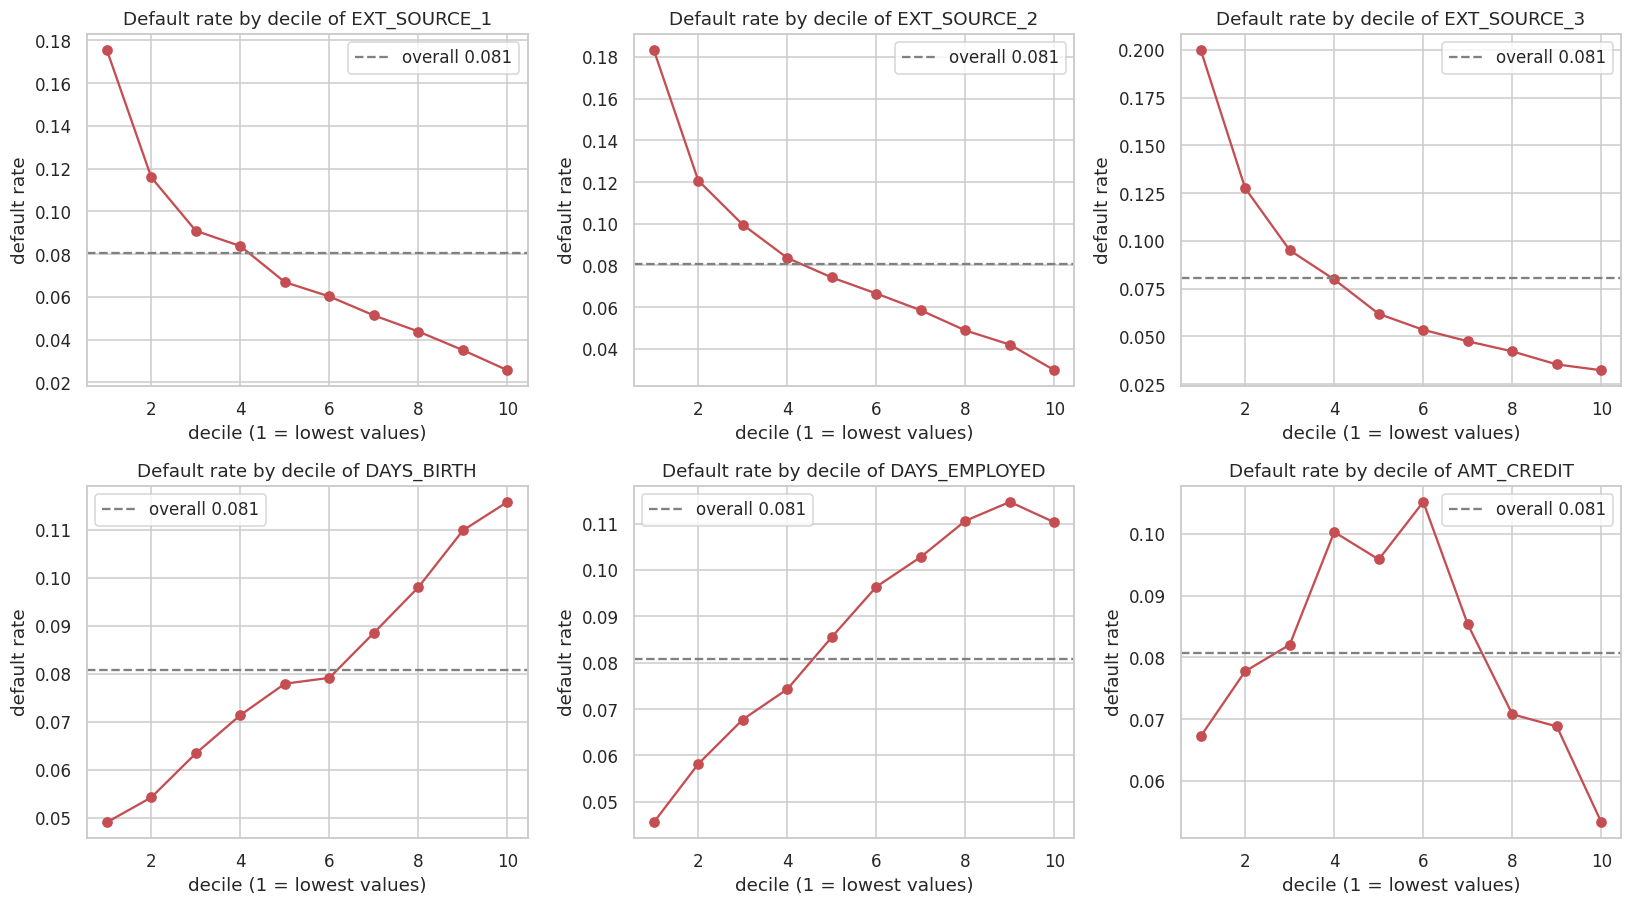

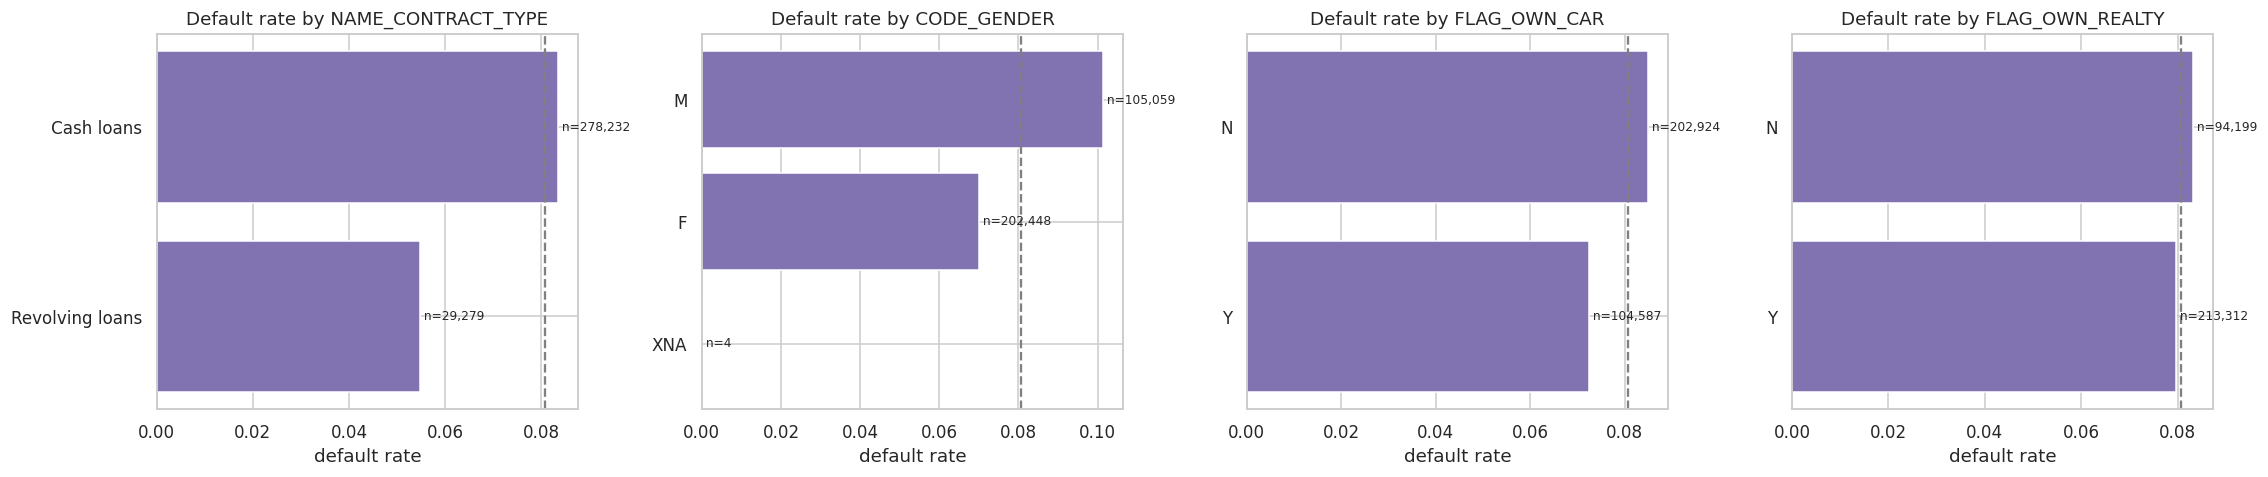

DAYS_EMPLOYED == 365243 (placeholder value): 55,374 rows (18.0%); default rate there = 0.054


In [10]:
if not RESTORED:
    # Default rate per decile of key numeric features: a monotonic trend means the feature is informative
    candidates = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
                  'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_INCOME_TOTAL', 'DAYS_ID_PUBLISH', 'DAYS_REGISTRATION']
    cols = [c for c in candidates if c in train][:6]
    if cols:
        nrow = int(np.ceil(len(cols) / 3))
        fig, axes = plt.subplots(nrow, 3, figsize=(15, 4.2 * nrow), squeeze=False)
        base = train[TARGET].mean()
        for ax, c in zip(axes.ravel(), cols):
            s = train[c].replace(365243, np.nan)
            b = pd.qcut(s, 10, duplicates='drop')
            r = train.groupby(b, observed=True)[TARGET].mean()
            ax.plot(range(1, len(r) + 1), r.values, marker='o', color='#C44E52')
            ax.axhline(base, ls='--', color='grey', label=f'overall {base:.3f}')
            ax.set_title(f'Default rate by decile of {c}'); ax.set_xlabel('decile (1 = lowest values)')
            ax.set_ylabel('default rate'); ax.legend()
        for ax in axes.ravel()[len(cols):]: ax.axis('off')
        plt.tight_layout(); plt.show()

    # Default rate by category for low-cardinality categorical columns
    cat_small = [c for c in train.select_dtypes(exclude='number').columns if train[c].nunique() <= 12][:4]
    if cat_small:
        fig, axes = plt.subplots(1, len(cat_small), figsize=(5.2 * len(cat_small), 4.5), squeeze=False)
        base = train[TARGET].mean()
        for ax, c in zip(axes.ravel(), cat_small):
            g = train.groupby(c, dropna=False)[TARGET].agg(['mean', 'size']).sort_values('mean')
            ax.barh(g.index.astype(str), g['mean'], color='#8172B2')
            ax.axvline(base, ls='--', color='grey')
            for i, (m, n) in enumerate(zip(g['mean'], g['size'])):
                ax.text(m, i, f' n={n:,}', va='center', fontsize=8)
            ax.set_title(f'Default rate by {c}'); ax.set_xlabel('default rate')
        plt.tight_layout(); plt.show()

    if 'DAYS_EMPLOYED' in train:
        n_anom = (train['DAYS_EMPLOYED'] == 365243).sum()
        print(f'DAYS_EMPLOYED == 365243 (placeholder value): {n_anom:,} rows ({n_anom/len(train):.1%}); '
              f'default rate there = {train.loc[train.DAYS_EMPLOYED == 365243, TARGET].mean():.3f}')

## 3. Feature engineering
Everything here is computed row by row or from unsupervised statistics on train+test together, so no target information leaks in. The product features of the external scores are the "cross features" step from the slides.

In [11]:
if not RESTORED:
    def sdiv(a, b):
        return a / b.replace(0, np.nan)

    def add_features(d):
        has = lambda *cols: all(c in d.columns for c in cols)

        # known anomaly: 365243 days employed means "not employed / unknown"
        if 'DAYS_EMPLOYED' in d:
            d['DAYS_EMPLOYED_ANOM'] = (d['DAYS_EMPLOYED'] == 365243).astype('int8')
            d['DAYS_EMPLOYED'] = d['DAYS_EMPLOYED'].replace(365243, np.nan)

        # age / time
        if 'DAYS_BIRTH' in d:
            d['AGE_YEARS'] = -d['DAYS_BIRTH'] / 365.25
        if has('DAYS_EMPLOYED', 'DAYS_BIRTH'):
            d['EMPLOYED_TO_AGE'] = sdiv(d['DAYS_EMPLOYED'], d['DAYS_BIRTH'])
        if has('DAYS_REGISTRATION', 'DAYS_BIRTH'):
            d['REG_TO_AGE'] = sdiv(d['DAYS_REGISTRATION'], d['DAYS_BIRTH'])
        if has('DAYS_ID_PUBLISH', 'DAYS_BIRTH'):
            d['ID_TO_AGE'] = sdiv(d['DAYS_ID_PUBLISH'], d['DAYS_BIRTH'])
        if has('DAYS_LAST_PHONE_CHANGE', 'DAYS_BIRTH'):
            d['PHONE_TO_AGE'] = sdiv(d['DAYS_LAST_PHONE_CHANGE'], d['DAYS_BIRTH'])
        if has('OWN_CAR_AGE', 'DAYS_BIRTH'):
            d['CAR_TO_AGE'] = sdiv(d['OWN_CAR_AGE'], -d['DAYS_BIRTH'] / 365.25)
        if has('OWN_CAR_AGE', 'DAYS_EMPLOYED'):
            d['CAR_TO_EMPLOYED'] = sdiv(d['OWN_CAR_AGE'], -d['DAYS_EMPLOYED'] / 365.25)

        # credit burden ratios
        if has('AMT_CREDIT', 'AMT_INCOME_TOTAL'):
            d['CREDIT_TO_INCOME'] = sdiv(d['AMT_CREDIT'], d['AMT_INCOME_TOTAL'])
        if has('AMT_ANNUITY', 'AMT_INCOME_TOTAL'):
            d['ANNUITY_TO_INCOME'] = sdiv(d['AMT_ANNUITY'], d['AMT_INCOME_TOTAL'])
        if has('AMT_ANNUITY', 'AMT_CREDIT'):
            d['ANNUITY_TO_CREDIT'] = sdiv(d['AMT_ANNUITY'], d['AMT_CREDIT'])
            d['CREDIT_TERM'] = sdiv(d['AMT_CREDIT'], d['AMT_ANNUITY'])
        if has('AMT_GOODS_PRICE', 'AMT_CREDIT'):
            d['GOODS_TO_CREDIT'] = sdiv(d['AMT_GOODS_PRICE'], d['AMT_CREDIT'])
            d['CREDIT_MINUS_GOODS'] = d['AMT_CREDIT'] - d['AMT_GOODS_PRICE']
        if has('AMT_GOODS_PRICE', 'AMT_INCOME_TOTAL'):
            d['GOODS_TO_INCOME'] = sdiv(d['AMT_GOODS_PRICE'], d['AMT_INCOME_TOTAL'])
        if has('AMT_INCOME_TOTAL', 'DAYS_EMPLOYED'):
            d['INCOME_PER_WORKDAY'] = sdiv(d['AMT_INCOME_TOTAL'], -d['DAYS_EMPLOYED'])
        if has('AMT_CREDIT', 'DAYS_BIRTH'):
            d['CREDIT_PER_AGE'] = sdiv(d['AMT_CREDIT'], -d['DAYS_BIRTH'])

        # household
        if has('AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS'):
            d['INCOME_PER_PERSON'] = sdiv(d['AMT_INCOME_TOTAL'], d['CNT_FAM_MEMBERS'])
        if has('AMT_CREDIT', 'CNT_FAM_MEMBERS'):
            d['CREDIT_PER_PERSON'] = sdiv(d['AMT_CREDIT'], d['CNT_FAM_MEMBERS'])
        if has('CNT_CHILDREN', 'CNT_FAM_MEMBERS'):
            d['CHILDREN_RATIO'] = sdiv(d['CNT_CHILDREN'], d['CNT_FAM_MEMBERS'])

        # external scores: usually the strongest signals; pairwise products are the "cross features"
        ext = [c for c in d.columns if c.startswith('EXT_SOURCE_')]
        if ext:
            e = d[ext]
            d['EXT_MEAN'] = e.mean(axis=1)
            d['EXT_STD']  = e.std(axis=1)
            d['EXT_MIN']  = e.min(axis=1)
            d['EXT_MAX']  = e.max(axis=1)
            d['EXT_PROD'] = e.prod(axis=1, min_count=1)
            d['EXT_NA_COUNT'] = e.isna().sum(axis=1).astype('int8')
            for i in range(len(ext)):
                for j in range(i + 1, len(ext)):
                    d[f'{ext[i]}_x_{ext[j]}'] = d[ext[i]] * d[ext[j]]
            if has('DAYS_BIRTH'):
                d['EXT_MEAN_X_AGE'] = d['EXT_MEAN'] * (-d['DAYS_BIRTH'] / 365.25)
            if 'CREDIT_TERM' in d:
                d['EXT_MEAN_X_CREDIT_TERM'] = d['EXT_MEAN'] * d['CREDIT_TERM']

        # flag / count aggregates
        docs = [c for c in d.columns if c.startswith('FLAG_DOCUMENT_')]
        if docs: d['DOCS_SUM'] = d[docs].sum(axis=1)
        bur = [c for c in d.columns if c.startswith('AMT_REQ_CREDIT_BUREAU_')]
        if bur: d['BUREAU_REQ_SUM'] = d[bur].sum(axis=1)
        cont = [c for c in ['FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE',
                            'FLAG_PHONE', 'FLAG_EMAIL'] if c in d]
        if cont: d['CONTACT_FLAGS_SUM'] = d[cont].sum(axis=1)
        mis = [c for c in d.columns if (c.startswith('REG_') or c.startswith('LIVE_')) and d[c].dtype != 'object']
        if mis: d['ADDR_MISMATCH_SUM'] = d[mis].sum(axis=1)
        if has('DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_30_CNT_SOCIAL_CIRCLE'):
            d['SOCIAL_DEF_RATIO_30'] = sdiv(d['DEF_30_CNT_SOCIAL_CIRCLE'], d['OBS_30_CNT_SOCIAL_CIRCLE'])
        if has('DEF_60_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE'):
            d['SOCIAL_DEF_RATIO_60'] = sdiv(d['DEF_60_CNT_SOCIAL_CIRCLE'], d['OBS_60_CNT_SOCIAL_CIRCLE'])

        # how a client compares with peers (unsupervised group statistics, no target used)
        for grp in ['ORGANIZATION_TYPE', 'OCCUPATION_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE']:
            if grp not in d: continue
            for val in ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'EXT_MEAN', 'DAYS_EMPLOYED', 'AGE_YEARS']:
                if val in d:
                    d[f'{val}_DIFF_{grp}'] = d[val] - d.groupby(grp)[val].transform('median')
        return d


    def aggregate_table(df, key, prefix):
        # per-client summary of an auxiliary table (mean/max/min/sum/std; one-hot categoricals)
        df = df.drop(columns=[c for c in df.columns if c.upper().startswith('SK_ID') and c != key])
        f64 = df.select_dtypes('float64').columns
        df[f64] = df[f64].astype('float32')
        obj = df.select_dtypes(include=['object', 'category']).columns.tolist()
        if obj:
            df = pd.get_dummies(df, columns=obj, dtype='uint8')
        agg = {}
        for c in df.columns:
            if c == key: continue
            agg[c] = ['mean', 'sum'] if df[c].dtype == 'uint8' else ['mean', 'max', 'min', 'sum', 'std']
        out = df.groupby(key).agg(agg)
        out.columns = [f'{prefix}_{a}_{b}'.upper() for a, b in out.columns]
        out[f'{prefix}_COUNT'] = df.groupby(key).size()
        return out.reset_index()


In [12]:
if not RESTORED:
    t0 = time.time()
    clean = lambda s: re.sub(r'[^0-9a-zA-Z_]', '_', s)
    raw_clean = {clean(c) for c in raw_feature_names}

    # Correcting the variables to train and test as loaded in cell 8MIrJxJ0JpNM
    train['__is_train'] = 1
    test['__is_train']  = 0
    full = pd.concat([train, test], ignore_index=True, sort=False)


    full = add_features(full)

    if USE_AUX_TABLES:
        for f in aux_files:
            try:
                # Skip description file or files without client ID
                if 'description' in f.lower(): continue
                if ID_COL not in pd.read_csv(f, nrows=5).columns: continue

                name = os.path.splitext(os.path.basename(f))[0][:12]
                print(f'Processing {name}...')

                # Read only first 100,000 rows in Quick mode to speed up processing
                if QUICK:
                    df_aux = pd.read_csv(f, nrows=100000)
                else:
                    df_aux = pd.read_csv(f)

                agg = aggregate_table(df_aux, ID_COL, name)
                full = full.merge(agg, on=ID_COL, how='left')
                print(f'merged {name}: +{agg.shape[1]-1} features')
                del df_aux, agg; gc.collect()
            except Exception as e:
                print('skipped', f, '->', e)

    # categorical encoding (unsupervised, so no leakage)
    cat_raw = [c for c in full.select_dtypes(include=['object', 'category']).columns if c != ID_COL]
    for c in cat_raw:
        if full[c].nunique() > 2:
            full[c + '_FREQ'] = full[c].map(full[c].value_counts(normalize=True)).astype('float32')
        full[c] = full[c].astype('category').cat.codes.astype('int16')

    full.columns = [clean(c) for c in full.columns]
    ID_C, TARGET_C = clean(ID_COL), clean(TARGET)
    cat_cols = [clean(c) for c in cat_raw]
    assert full.columns.is_unique

    f64 = full.select_dtypes('float64').columns
    full[f64] = full[f64].astype('float32')
    full = full.replace([np.inf, -np.inf], np.nan)

    is_train = full['__is_train'] == 1
    y = full.loc[is_train, TARGET_C].astype(int).reset_index(drop=True)
    test_ids = full.loc[~is_train, ID_C].reset_index(drop=True)
    features = [c for c in full.columns if c not in (ID_C, TARGET_C, '__is_train')]
    const = [c for c in features if full.loc[is_train, c].nunique(dropna=True) <= 1]
    features = [c for c in features if c not in const]
    cat_cols = [c for c in cat_cols if c in features]
    base_features = [c for c in features if c in raw_clean]

    X  = full.loc[is_train, features].reset_index(drop=True)
    Xt = full.loc[~is_train, features].reset_index(drop=True)
    del full; gc.collect()
    print(f'features={len(features)} (original {len(base_features)}, engineered {len(features)-len(base_features)}; ')
    print(f'dropped {len(const)} constant)  cat={len(cat_cols)}  train={X.shape}  test={Xt.shape}  [{time.time()-t0:.0f}s]')

Processing POS_CASH_bal...
merged POS_CASH_bal: +44 features
Processing bureau...
merged bureau: +107 features
Processing credit_card_...
merged credit_card_: +115 features
Processing installments...
merged installments: +31 features
Processing previous_app...
merged previous_app: +382 features
features=868 (original 120, engineered 748; 
dropped 4 constant)  cat=16  train=(307511, 868)  test=(48744, 868)  [196s]


In [13]:
# Save a checkpoint so a Colab restart does not cost you Sections 1-3
if not RESTORED:
    keep = ['X', 'Xt', 'y', 'test_ids', 'features', 'cat_cols', 'raw_clean', 'ID_COL', 'TARGET', 'sample', 'base_features']
    tmp = CKPT + '.tmp'
    with open(tmp, 'wb') as fh:
        pickle.dump(dict(signature=SIGNATURE, state={k: globals()[k] for k in keep}), fh, protocol=4)
    os.replace(tmp, CKPT)
    print(f'Checkpoint saved ({os.path.getsize(CKPT)/1e6:.0f} MB): {CKPT}')

Checkpoint saved (1284 MB): /content/drive/MyDrive/competition_output/artifacts/features_checkpoint.pkl


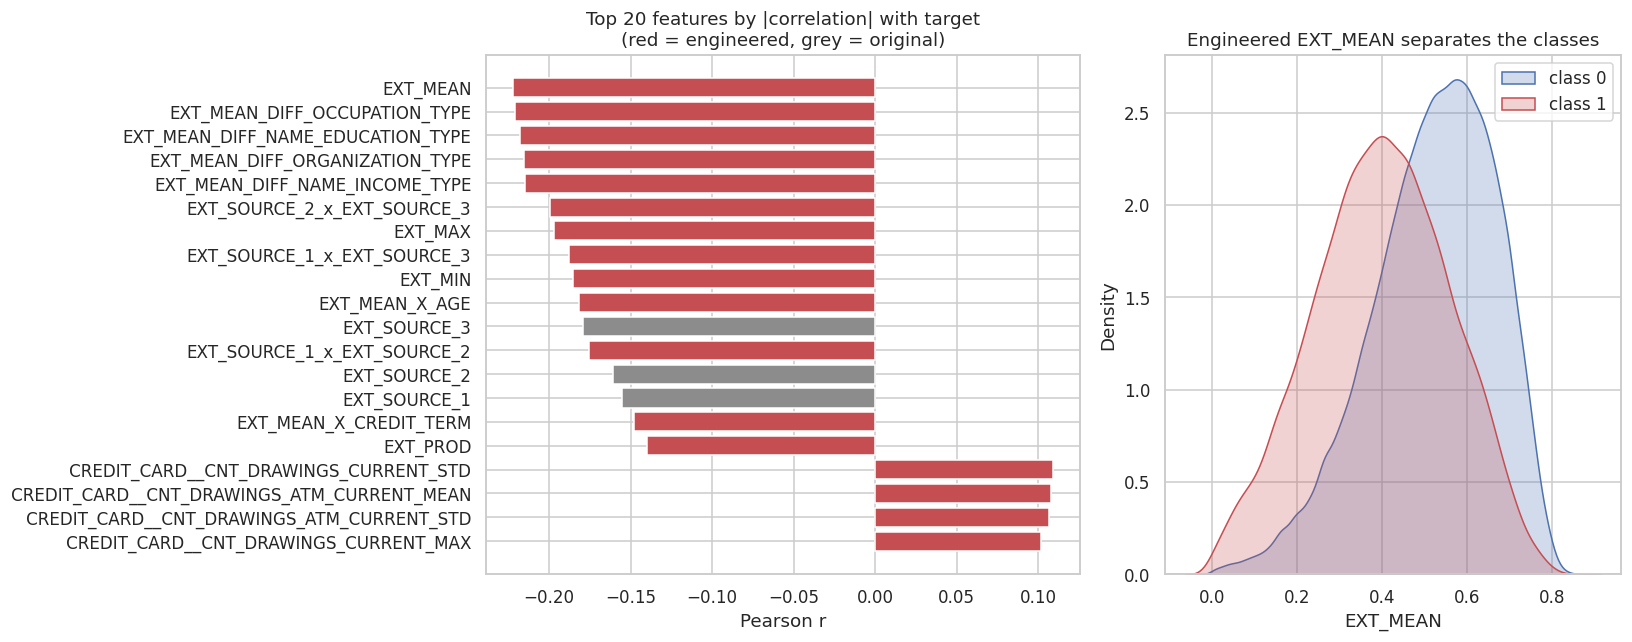

In [14]:
if not RESTORED:
    # Which engineered features carry signal? Compare correlation with the target for original vs engineered columns
    corr = X.corrwith(y).dropna()
    top = corr.reindex(corr.abs().sort_values(ascending=False).head(20).index)
    colors = ['#8C8C8C' if c in raw_clean else '#C44E52' for c in top.index]
    fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.3, 1]})
    axes[0].barh(top.index[::-1], top.values[::-1], color=colors[::-1])
    axes[0].set_title('Top 20 features by |correlation| with target\n(red = engineered, grey = original)')
    axes[0].set_xlabel('Pearson r')

    if 'EXT_MEAN' in X:
        for k in (0, 1):
            sns.kdeplot(X.loc[y == k, 'EXT_MEAN'].dropna(), ax=axes[1], color=PALETTE[k], fill=True, alpha=.25, label=f'class {k}')
        axes[1].set_title('Engineered EXT_MEAN separates the classes'); axes[1].legend()
    elif 'CREDIT_TO_INCOME' in X:
        for k in (0, 1):
            sns.kdeplot(X.loc[y == k, 'CREDIT_TO_INCOME'].clip(upper=X['CREDIT_TO_INCOME'].quantile(.99)).dropna(),
                        ax=axes[1], color=PALETTE[k], fill=True, alpha=.25, label=f'class {k}')
        axes[1].set_title('CREDIT_TO_INCOME by class'); axes[1].legend()
    else:
        axes[1].axis('off')
    plt.tight_layout(); plt.show()

## 4. Validation framework
One fixed set of stratified folds is shared by every model, which is what makes out-of-fold (OOF) predictions comparable and blendable. The adversarial check asks whether a model can tell train rows from test rows: an AUC near 0.5 means the test set resembles train, so your CV score should track the leaderboard.

In [15]:
from sklearn.model_selection import StratifiedKFold
import lightgbm as lgb

folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(X, y))
fold_scores = lambda oof: [score_fn(y.iloc[va], oof[va]) for _, va in folds]

# ---- adversarial validation (always reported as AUC) ----
adv_X = pd.concat([X, Xt], ignore_index=True)
adv_y = np.r_[np.zeros(len(X)), np.ones(len(Xt))]
adv_oof = np.zeros(len(adv_X)); adv_imp = np.zeros(len(features))
for tr, va in StratifiedKFold(3, shuffle=True, random_state=SEED).split(adv_X, adv_y):
    m = lgb.LGBMClassifier(n_estimators=100, learning_rate=0.1, num_leaves=31, subsample=0.5,
                           subsample_freq=1, colsample_bytree=0.5, verbose=-1, random_state=SEED)
    m.fit(adv_X.iloc[tr], adv_y[tr])
    adv_oof[va] = m.predict_proba(adv_X.iloc[va])[:, 1]; adv_imp += m.feature_importances_
adv_auc = roc_auc_score(adv_y, adv_oof)
print(f'Adversarial AUC (train vs test): {adv_auc:.4f} ->',
      'test resembles train; CV should track the leaderboard' if adv_auc < 0.6 else
      'noticeable drift; consider dropping the features listed below')
if adv_auc >= 0.55:
    print(pd.Series(adv_imp, index=features).sort_values(ascending=False).head(10).to_string())
del adv_X, adv_y, adv_oof; gc.collect()

# ---- reusable LightGBM fold / CV functions (used for baseline, selection, tuning, final) ----
def lgb_fold(cols, params, tr, va, seed, predict_test=False):
    m = lgb.LGBMClassifier(n_estimators=MAX_TREES, metric=M['lgb'], importance_type='gain',
                           random_state=seed, verbose=-1, n_jobs=-1, max_bin=MAX_BIN, force_col_wise=True, **params)
    m.fit(X.iloc[tr][cols], y.iloc[tr], eval_set=[(X.iloc[va][cols], y.iloc[va])],
          categorical_feature=[c for c in cat_cols if c in cols] or 'auto',
          callbacks=[lgb.early_stopping(PATIENCE, first_metric_only=True, verbose=False)])
    p_va = m.predict_proba(X.iloc[va][cols])[:, 1]
    p_te = m.predict_proba(Xt[cols])[:, 1] if predict_test else None
    return p_va, p_te, m.feature_importances_

def lgb_cv(cols, params, folds_used=None, seed=SEED):
    folds_used = folds_used or folds
    oof = np.full(len(X), np.nan); imp = np.zeros(len(cols)); scores = []
    for k, (tr, va) in enumerate(folds_used):
        p, _, i = lgb_fold(cols, params, tr, va, seed + k)
        oof[va] = p; imp += i / len(folds_used); scores.append(score_fn(y.iloc[va], p))
    return dict(oof=oof, scores=scores, imp=pd.Series(imp, index=cols))

LGB_QUICK = dict(learning_rate=0.1, num_leaves=31, subsample=0.8, subsample_freq=1, colsample_bytree=P['col_sel'])

# ---- generic CV runner with caching and logging (used for the final models) ----
RUN_KEY = None
IMP = {}
def cache_file(name):
    return os.path.join(ART_DIR, f'{re.sub(r"[^0-9a-zA-Z]+", "_", name)}_{RUN_KEY}.npz')

def run_cv(name, fit_fold, note=''):
    path = cache_file(name)
    if RESUME and os.path.exists(path):
        d = np.load(path); oof, pred = d['oof'], d['pred']
        log_exp(name, fold_scores(oof), len(features), 0, '(loaded from cache)')
        return oof, pred
    t0 = time.time(); oof = np.zeros(len(X)); pred = np.zeros(len(Xt))
    for k, (tr, va) in enumerate(folds):
        p_va, p_te = fit_fold(k, tr, va)
        oof[va] = p_va; pred += p_te / len(folds)
        print(f'  {name} fold {k}: {score_fn(y.iloc[va], p_va):.5f}')
    np.savez_compressed(path, oof=oof, pred=pred)
    log_exp(name, fold_scores(oof), len(features), time.time() - t0, note)
    return oof, pred

Adversarial AUC (train vs test): 0.9648 -> noticeable drift; consider dropping the features listed below
GOODS_TO_CREDIT                   749.0
ANNUITY_TO_CREDIT                 636.0
CREDIT_TERM                       613.0
BUREAU_DAYS_CREDIT_ENDDATE_MAX    314.0
CREDIT_MINUS_GOODS                249.0
PREVIOUS_APP_DAYS_DECISION_MAX    148.0
BUREAU_AMT_ANNUITY_STD            136.0
AMT_GOODS_PRICE                   134.0
AMT_CREDIT                        131.0
BUREAU_AMT_ANNUITY_MAX            130.0


## 5. Baseline and feature selection
1. **Baseline:** LightGBM on the original columns only. Every later number is compared with this.
2. **All features:** the same model with the engineered features added. If this is not better, the features are not helping.
3. **Selection:** train on the full set, rank features by gain, and test a few smaller sets. We keep the smallest set that scores within a small tolerance of the best, because fewer noisy features usually generalize better and train faster.

**Speed (fast profile):** the comparisons use the first 3 folds only, with a higher learning rate and coarser bins, and only the
top-40% candidate is tried besides all features and drop-zero-gain. The final models still use all 5 folds.

In [16]:

import time, re, gc, json, hashlib
import numpy as np
import pandas as pd

# ---- 0. Pre-flight: names this cell needs from earlier cells ----
REQUIRED = ['X', 'Xt', 'y', 'features', 'cat_cols', 'folds', 'lgb_cv', 'LGB_QUICK', 'log_exp',
            'EXPERIMENTS', 'score_fn', 'SEED', 'N_FOLDS', 'METRIC', 'QUICK', 'N_SEEDS_LGB', 'MAX_TREES',
            'SEL_FOLDS', 'SEL_FRACS', 'SPEED']
missing = [n for n in REQUIRED if n not in globals()]
if missing:
    raise RuntimeError('Run the earlier cells first: use Runtime -> Restart session, then Run all. '
                       'Still missing: ' + ', '.join(missing))

# ---- 1. Make the cell idempotent: always start from the full feature set ----
if 'X_all' in globals() and id(X) == globals().get('_SELECTED_X_ID'):
    X, Xt = X_all, Xt_all
    features, cat_cols = list(features_all), list(cat_cols_all)
    print('Re-run detected: restored the full feature set before selecting again.')
else:
    X_all, Xt_all = X, Xt
    features_all, cat_cols_all = list(features), list(cat_cols)
EXPERIMENTS[:] = [e for e in EXPERIMENTS if not e['experiment'].startswith(('1.', '2.', '3.'))]

# ---- 2. Which columns are "original"? (needed for the baseline) ----
if 'raw_clean' not in globals():
    clean = lambda s: re.sub(r'[^0-9a-zA-Z_]', '_', s)
    if 'raw_feature_names' not in globals():
        try:
            header = pd.read_csv(train_path, nrows=2).columns
            raw_feature_names = [c for c in header if c not in (ID_COL, TARGET)]
        except NameError:
            raw_feature_names = []
    raw_clean = {clean(c) for c in raw_feature_names}
base_features = [c for c in features_all if c in raw_clean]

# ---- 3. Baseline vs all features (fast profile compares on the first SEL_FOLDS folds only) ----
folds_sel = folds[:SEL_FOLDS]
sel_note = f'({SEL_FOLDS} of {N_FOLDS} folds)' if SEL_FOLDS < N_FOLDS else ''
if base_features:
    t0 = time.time()
    r_base = lgb_cv(base_features, LGB_QUICK, folds_sel)
    log_exp('1. Baseline (original columns)', r_base['scores'], len(base_features), time.time() - t0, sel_note)
else:
    print('WARNING: could not identify the original columns, so the baseline step is skipped. '
          'Re-run the Load cell (Section 1) if you want it.')

t0 = time.time()
r_all = lgb_cv(features, LGB_QUICK, folds_sel)
log_exp('2. + Engineered features', r_all['scores'], len(features), time.time() - t0, sel_note)

# ---- 4. Candidate feature sets ranked by gain ----
rank = r_all['imp'].sort_values(ascending=False)
candidates = {'all features': list(features)}
nonzero = [c for c in features if r_all['imp'][c] > 0]
if len(nonzero) < len(features):
    candidates['drop zero-gain'] = nonzero
for frac in SEL_FRACS:
    candidates[f'top {int(round(frac * 100))}% by gain'] = list(rank.index[:max(20, int(len(rank) * frac))])
candidates = {k: v for k, v in candidates.items() if len(v) <= len(features)}

sel_rows, cand_scores = [], {}
for name, cols in candidates.items():
    sc = r_all['scores'] if name == 'all features' else lgb_cv(cols, LGB_QUICK, folds_sel)['scores']
    cand_scores[name] = sc
    sel_rows.append((name, len(cols), np.mean(sc), np.std(sc)))
sel = pd.DataFrame(sel_rows, columns=['feature set', 'n_features', 'score', 'std']).sort_values('score', ascending=False)
print(sel.to_string(index=False))

# ---- 5. Choose the smallest set within tolerance of the best ----
TOL = 1e-4
best = sel['score'].max()
chosen_name = sel[sel['score'] >= best - TOL].sort_values('n_features').iloc[0]['feature set']
chosen = candidates[chosen_name]
print(f'\nChosen: {chosen_name} ({len(chosen)} of {len(features)} features)')

imp_sel = r_all['imp'][chosen]
features = list(chosen)
cat_cols = [c for c in cat_cols if c in features]
X, Xt = X_all[features], Xt_all[features]
_SELECTED_X_ID = id(X)
log_exp('3. Selected feature set', cand_scores[chosen_name], len(features), 0, f'({chosen_name}) {sel_note}')

# ---- 6. Cache id for the later model cells (changes whenever the feature set changes) ----
key_parts = [SEED, N_FOLDS, METRIC, QUICK, N_SEEDS_LGB, MAX_TREES, features, int(len(X)), int(len(Xt))]
if SPEED != 'full':
    key_parts.append(SPEED)
RUN_KEY = hashlib.md5(json.dumps(key_parts).encode()).hexdigest()[:10]
print('Run key (cache id):', RUN_KEY)
gc.collect()


[1. Baseline (original columns)] ROC AUC: 0.75667 (+/- 0.00466)  120 features  71s (3 of 5 folds)
[2. + Engineered features] ROC AUC: 0.78252 (+/- 0.00381)  868 features  409s (3 of 5 folds)
    feature set  n_features    score      std
top 40% by gain         347 0.782763 0.003734
   all features         868 0.782520 0.003814
 drop zero-gain         720 0.781993 0.003656

Chosen: top 40% by gain (347 of 868 features)
[3. Selected feature set] ROC AUC: 0.78276 (+/- 0.00373)  347 features  0s (top 40% by gain) (3 of 5 folds)
Run key (cache id): 84cb3e4cad


1074

## 6. LightGBM with Optuna tuning
Tuning uses 3 of the 5 folds and a moderate learning rate to keep each trial cheap. The final model reuses the best parameters with a lower learning rate, all 5 folds, and 3 seeds averaged.

**Speed (fast profile):** 15 trials with a 10-minute limit, a higher tuning learning rate, and Optuna's median pruner, which stops
clearly bad trials after their first folds. The final model uses 1 seed and a learning rate of 0.05.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 17.9 MB/s eta 0:00:00
Best tuning score: 0.78469
{'num_leaves': 34, 'max_depth': 10, 'min_child_samples': 144, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.29361118426546196, 'reg_alpha': 0.004207053950287938, 'reg_lambda': 0.001819899369726822, 'min_split_gain': 0.4330880728874676}
Trials completed: 3 | pruned early: 0


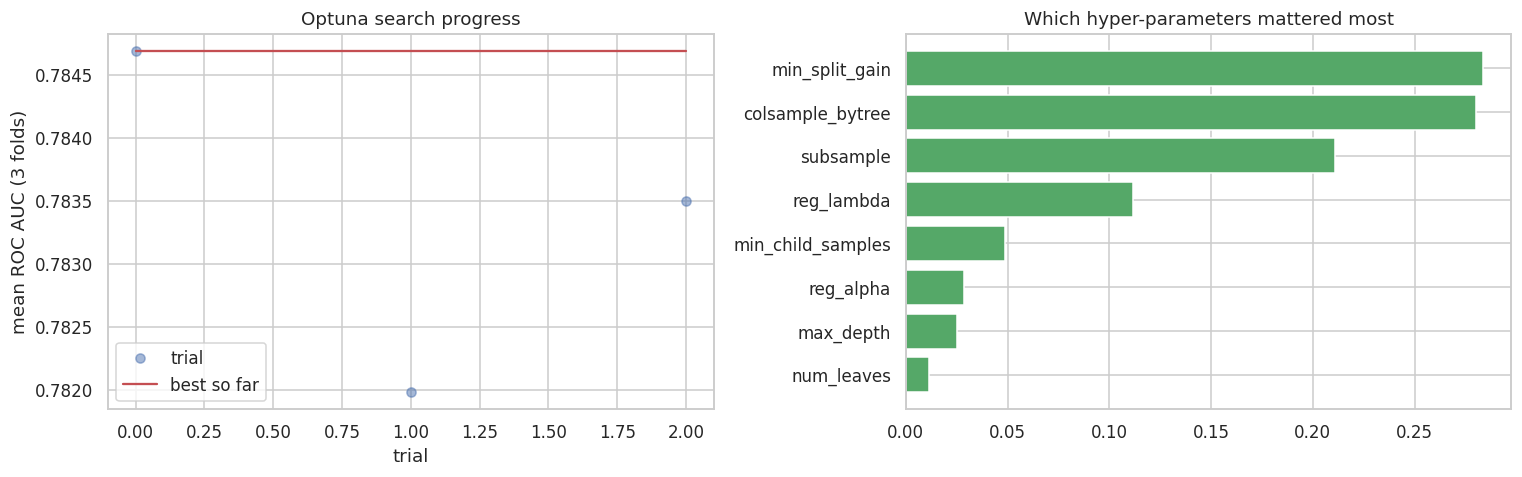

In [17]:
!pip -q install optuna catboost
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = dict(
        learning_rate=TUNE_LR,
        num_leaves=trial.suggest_int('num_leaves', 16, 128, log=True),
        max_depth=trial.suggest_int('max_depth', 3, 10),
        min_child_samples=trial.suggest_int('min_child_samples', 20, 300, log=True),
        subsample=trial.suggest_float('subsample', 0.6, 1.0), subsample_freq=1,
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.2, 0.8),
        reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 30, log=True),
        min_split_gain=trial.suggest_float('min_split_gain', 0.0, 0.5),
    )
    scores = []
    for step, (tr, va) in enumerate(folds[:3]):
        p, _, _ = lgb_fold(features, params, tr, va, SEED + step)
        scores.append(score_fn(y.iloc[va], p))
        trial.report(float(np.mean(scores)), step)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return float(np.mean(scores))

study_path = os.path.join(ART_DIR, f'optuna_params_{RUN_KEY}.json')
if RESUME and os.path.exists(study_path):
    best_params = json.load(open(study_path)); study = None
    print('Loaded tuned parameters from cache:', best_params)
else:
    pruner = optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1) if SPEED == 'fast' else optuna.pruners.NopPruner()
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED), pruner=pruner)
    study.optimize(objective, n_trials=OPTUNA_TRIALS, timeout=OPTUNA_TIMEOUT)
    best_params = study.best_params
    json.dump(best_params, open(study_path, 'w'))
    print('Best tuning score:', round(study.best_value, 5)); print(best_params)

    print('Trials completed:', sum(t.state.name == 'COMPLETE' for t in study.trials),
          '| pruned early:', sum(t.state.name == 'PRUNED' for t in study.trials))
    vals = [t.value for t in study.trials if t.value is not None]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(vals, 'o', alpha=.5, label='trial'); axes[0].plot(np.maximum.accumulate(vals), color='#C44E52', label='best so far')
    axes[0].set_title('Optuna search progress'); axes[0].set_xlabel('trial'); axes[0].set_ylabel(f'mean {M["label"]} (3 folds)'); axes[0].legend()
    try:
        ip = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
        axes[1].barh(ip.index, ip.values, color='#55A868'); axes[1].set_title('Which hyper-parameters mattered most')
    except Exception as e:
        axes[1].axis('off'); print('param importance unavailable:', e)
    plt.tight_layout(); plt.show()

Training 5 folds x 1 seeds = 5 LightGBM models.
  4. LightGBM tuned fold 0: 0.78514
  4. LightGBM tuned fold 1: 0.79219
  4. LightGBM tuned fold 2: 0.78422
  4. LightGBM tuned fold 3: 0.79315
  4. LightGBM tuned fold 4: 0.78581
[4. LightGBM tuned] ROC AUC: 0.78810 (+/- 0.00378)  347 features  695s (1 seeds)


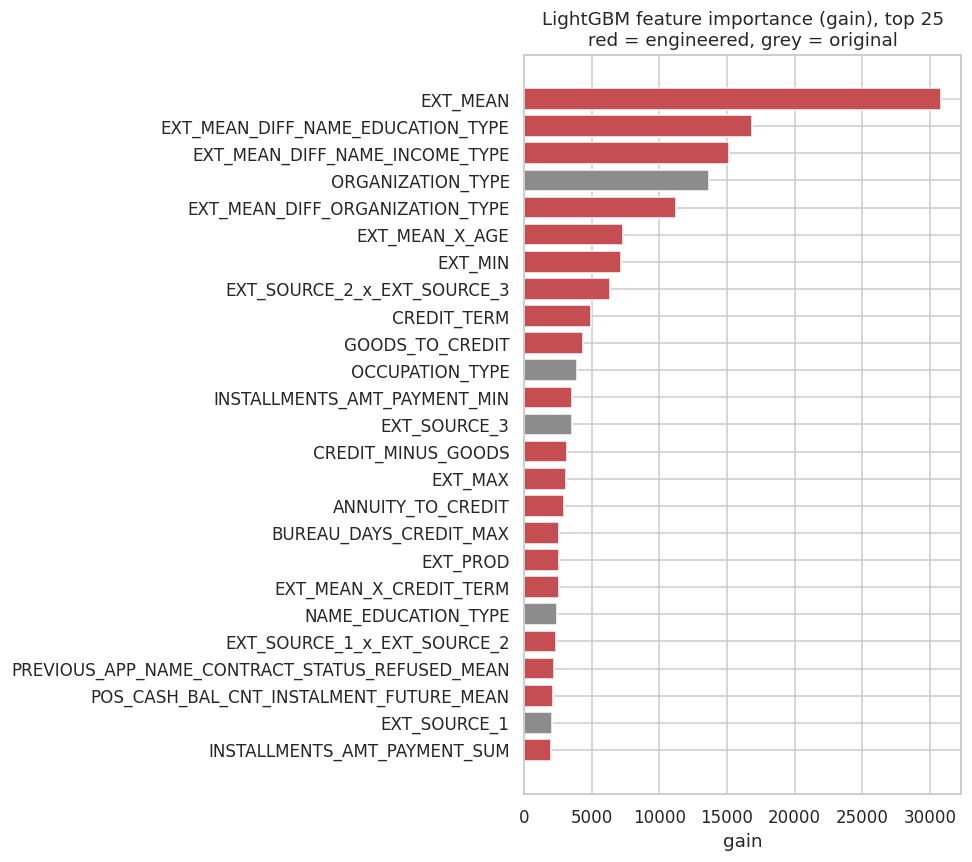

In [18]:

import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- 0. Pre-flight: stop with a clear message instead of silently guessing ----
REQUIRED = ['X', 'Xt', 'y', 'features', 'folds', 'lgb_fold', 'run_cv', 'cache_file', 'log_exp',
            'RUN_KEY', 'SEED', 'N_FOLDS', 'N_SEEDS_LGB', 'QUICK', 'raw_clean', 'ART_DIR', 'FINAL_LR']
missing = [n for n in REQUIRED if n not in globals()]
if missing or RUN_KEY is None:
    raise RuntimeError(
        'Earlier cells have not run in this session (' + ', '.join(missing or ['RUN_KEY']) + ' missing). '
        'Use Runtime -> Restart session, then Run all. Saved model results are reused automatically, '
        'so this will not repeat finished work.')

# ---- 1. Tuned parameters: from this session, or from the cache for THIS exact run ----
if 'best_params' not in globals():
    p = os.path.join(ART_DIR, f'optuna_params_{RUN_KEY}.json')
    if not os.path.exists(p):
        raise RuntimeError('best_params not found: run the Optuna cell above first.')
    best_params = json.load(open(p))
    print('Loaded tuned parameters from cache:', best_params)

best_lgb = dict(best_params, learning_rate=FINAL_LR, subsample_freq=1)
IMP = globals().get('IMP', {})
IMP['LightGBM'] = pd.Series(0.0, index=features)

def lgb_final_fold(k, tr, va):
    pv = np.zeros(len(va)); pt = np.zeros(len(Xt))
    for s in range(N_SEEDS_LGB):
        p_va, p_te, imp = lgb_fold(features, best_lgb, tr, va, SEED + 100 * s + k, predict_test=True)
        pv += p_va / N_SEEDS_LGB; pt += p_te / N_SEEDS_LGB
        IMP['LightGBM'] += pd.Series(imp, index=features) / (N_SEEDS_LGB * N_FOLDS)
    return pv, pt

oofs = globals().get('oofs', {}); preds = globals().get('preds', {})
if not os.path.exists(cache_file('4. LightGBM tuned')):
    print(f'Training {N_FOLDS} folds x {N_SEEDS_LGB} seeds = {N_FOLDS * N_SEEDS_LGB} LightGBM models.')
    if N_SEEDS_LGB > 1:
        print('Tip: set N_SEEDS_LGB = 1 in the config cell to make this roughly N times faster.')
oofs['LightGBM'], preds['LightGBM'] = run_cv('4. LightGBM tuned', lgb_final_fold, f'({N_SEEDS_LGB} seeds)')

# ---- 2. Feature-importance plot (importances are not stored in the cache) ----
imp_plot = IMP['LightGBM'] if IMP['LightGBM'].sum() > 0 else globals().get('imp_sel')
if imp_plot is not None and len(imp_plot) > 0:
    top = imp_plot.sort_values(ascending=False).head(25)
    plt.figure(figsize=(9, 8))
    plt.barh(top.index[::-1], top.values[::-1],
             color=['#8C8C8C' if c in raw_clean else '#C44E52' for c in top.index[::-1]])
    plt.title('LightGBM feature importance (gain), top 25\nred = engineered, grey = original'); plt.xlabel('gain')
    plt.tight_layout(); plt.show()
else:
    print('Importance plot skipped (results were loaded from cache). Set RESUME = False to regenerate it.')


## 7. XGBoost and CatBoost
Different algorithms make different mistakes, so blending them helps more than blending three copies of one model. They use the same folds and the same feature set.

**Speed (fast profile):** higher learning rate, fewer trees, smaller early-stopping patience, and coarser bins. If a GPU runtime is
selected (Runtime -> Change runtime type), both models use it automatically.

In [19]:
import shutil, subprocess
import xgboost as xgb

def gpu_available():
    try:
        return shutil.which('nvidia-smi') is not None and subprocess.run(['nvidia-smi'], capture_output=True).returncode == 0
    except Exception:
        return False

GPU = gpu_available()
P7 = PROFILE[SPEED_S7]
S7_TAG = '' if SPEED_S7 == 'full' else ' (fast)'
print(f'Section 7 profile: {SPEED_S7} | GPU runtime detected: {GPU}')
if not GPU:
    print('Tip: Runtime -> Change runtime type -> T4 GPU makes XGBoost and CatBoost much faster '
          '(your saved features and results are reused after the restart).')

xgb_device = dict(device='cuda') if GPU and int(xgb.__version__.split('.')[0]) >= 2 else {}
def xgb_fold(k, tr, va):
    m = xgb.XGBClassifier(
        n_estimators=50 if QUICK else P7['xgb_trees'], learning_rate=0.2 if QUICK else P7['xgb_lr'],
        max_depth=5, min_child_weight=10, subsample=0.8, colsample_bytree=0.5,
        reg_alpha=0.5, reg_lambda=5.0, gamma=0.1, tree_method='hist', max_bin=P7['xgb_bins'],
        eval_metric=M['xgb'], early_stopping_rounds=20 if QUICK else P7['patience7'],
        random_state=SEED + k, n_jobs=-1, **xgb_device)
    m.fit(X.iloc[tr], y.iloc[tr], eval_set=[(X.iloc[va], y.iloc[va])], verbose=False)
    return m.predict_proba(X.iloc[va])[:, 1], m.predict_proba(Xt)[:, 1]

oofs['XGBoost'], preds['XGBoost'] = run_cv('5. XGBoost' + S7_TAG, xgb_fold)

Section 7 profile: fast | GPU runtime detected: False
Tip: Runtime -> Change runtime type -> T4 GPU makes XGBoost and CatBoost much faster (your saved features and results are reused after the restart).
  5. XGBoost (fast) fold 0: 0.78471
  5. XGBoost (fast) fold 1: 0.79286
  5. XGBoost (fast) fold 2: 0.78475
  5. XGBoost (fast) fold 3: 0.79088
  5. XGBoost (fast) fold 4: 0.78486
[5. XGBoost (fast)] ROC AUC: 0.78761 (+/- 0.00353)  347 features  2964s 


In [20]:
from catboost import CatBoostClassifier

cat_idx = [features.index(c) for c in cat_cols]
cat_hw = dict(task_type='GPU') if GPU else dict(thread_count=-1)
cat_extra = dict(border_count=P7['cat_borders'], bootstrap_type='Bernoulli', subsample=0.8) if SPEED_S7 == 'fast' else {}
def cat_fold(k, tr, va):
    m = CatBoostClassifier(
        iterations=60 if QUICK else P7['cat_iters'], learning_rate=0.2 if QUICK else P7['cat_lr'], depth=6, l2_leaf_reg=8,
        eval_metric=M['cat'], od_type='Iter', od_wait=20 if QUICK else P7['patience7'],
        random_seed=SEED + k, verbose=0, cat_features=cat_idx, **cat_hw, **cat_extra)
    m.fit(X.iloc[tr], y.iloc[tr], eval_set=(X.iloc[va], y.iloc[va]), use_best_model=True)
    return m.predict_proba(X.iloc[va])[:, 1], m.predict_proba(Xt)[:, 1]

oofs['CatBoost'], preds['CatBoost'] = run_cv('6. CatBoost' + S7_TAG, cat_fold)

  6. CatBoost (fast) fold 0: 0.78474
  6. CatBoost (fast) fold 1: 0.79218
  6. CatBoost (fast) fold 2: 0.78345
  6. CatBoost (fast) fold 3: 0.79210
  6. CatBoost (fast) fold 4: 0.78375
[6. CatBoost (fast)] ROC AUC: 0.78725 (+/- 0.00402)  347 features  3126s 


## 8. Blend, judged fairly

In [21]:
from scipy.optimize import minimize

names = list(oofs)
O = np.column_stack([oofs[n] for n in names]); P = np.column_stack([preds[n] for n in names])

def fit_equal(Ob, yb):
    return lambda Op: Op.mean(axis=1)

def fit_weighted(Ob, yb):
    k = Ob.shape[1]
    f = lambda w: -score_fn(yb, Ob @ (np.abs(w) / np.abs(w).sum()))
    r = minimize(f, np.ones(k) / k, method='Nelder-Mead', options=dict(xatol=1e-3, fatol=1e-7, maxiter=300))
    w = np.abs(r.x) / np.abs(r.x).sum()
    fit_weighted.last = w
    return lambda Op: Op @ w

methods = {'equal average': fit_equal, 'optimized weights': fit_weighted}
for i, n in enumerate(names):
    methods[f'only {n}'] = (lambda i: (lambda Ob, yb: (lambda Op: Op[:, i])))(i)

outer = StratifiedKFold(5, shuffle=True, random_state=SEED + 7)
nested = {}
for mname, fit in methods.items():
    sc = []
    for tr, va in outer.split(O, y):
        sc.append(score_fn(y.iloc[va], fit(O[tr], y.iloc[tr])(O[va])))
    nested[mname] = sc
tbl = pd.DataFrame({k: [np.mean(v), np.std(v)] for k, v in nested.items()}, index=['score', 'std']).T.sort_values('score', ascending=False)
print(tbl.round(5).to_string())

best_method = tbl.index[0]
if tbl.loc['equal average', 'score'] >= tbl.loc[best_method, 'score'] - 5e-5:
    best_method = 'equal average'      # robustness: keep the simple blend unless something is clearly better
print('\nChosen blend:', best_method)

blender = methods[best_method](O, y)
final_oof, final_pred = blender(O), blender(P)
if best_method == 'optimized weights':
    print('Weights:', dict(zip(names, np.round(fit_weighted.last, 3))))
log_exp(f'7. Blend ({best_method})', nested[best_method], len(features), 0, '(nested CV, unbiased)')

                     score      std
equal average      0.79117  0.00184
optimized weights  0.79112  0.00182
only LightGBM      0.78806  0.00168
only XGBoost       0.78756  0.00241
only CatBoost      0.78723  0.00186

Chosen blend: equal average
[7. Blend (equal average)] ROC AUC: 0.79117 (+/- 0.00184)  347 features  0s (nested CV, unbiased)


## 9. Results
Error bars are the spread across folds. Differences smaller than the bars are probably noise, so prefer changes that clearly move the score.

                    experiment  n_features   score     std  seconds                             note
1. Baseline (original columns)         120 0.75667 0.00466       71                   (3 of 5 folds)
      2. + Engineered features         868 0.78252 0.00381      409                   (3 of 5 folds)
       3. Selected feature set         347 0.78276 0.00373        0 (top 40% by gain) (3 of 5 folds)
             4. LightGBM tuned         347 0.78810 0.00378      695                        (1 seeds)
             5. XGBoost (fast)         347 0.78761 0.00353     2964                                 
            6. CatBoost (fast)         347 0.78725 0.00402     3126                                 
      7. Blend (equal average)         347 0.79117 0.00184        0            (nested CV, unbiased)


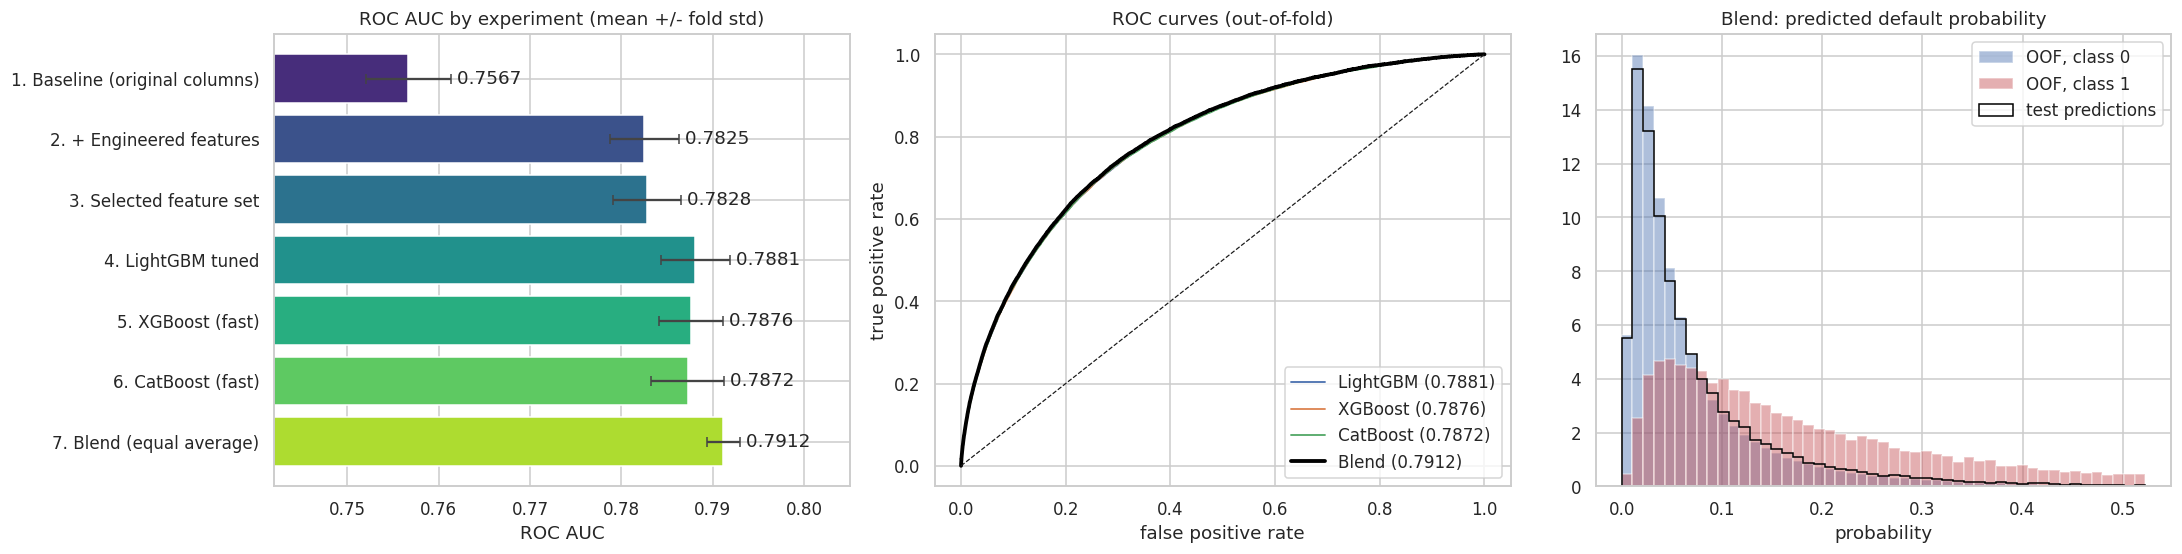

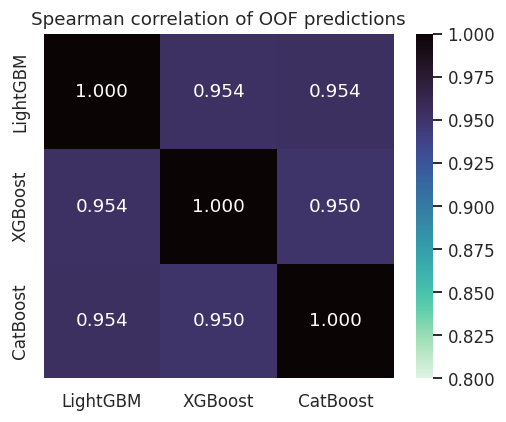

In [22]:
res = pd.DataFrame(EXPERIMENTS)
disp = res.copy()
if METRIC != 'auc':
    disp['score'] = -disp['score']
print(disp.round(5).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))
colors = sns.color_palette('viridis', len(res))
axes[0].barh(res['experiment'][::-1], res['score'][::-1], xerr=res['std'][::-1], color=colors[::-1], ecolor='#444', capsize=3)
lo = (res['score'] - res['std']).min(); hi = (res['score'] + res['std']).max()
axes[0].set_xlim(lo - 0.01, hi + 0.012)
for i, (s, e) in enumerate(zip(res['score'][::-1], res['std'][::-1])):
    axes[0].text(s + e, i, f' {s:.4f}', va='center')
axes[0].set_title(f'{M["label"]} by experiment (mean +/- fold std)'); axes[0].set_xlabel(M['label'])

for n in names:
    fpr, tpr, _ = roc_curve(y, oofs[n]); axes[1].plot(fpr, tpr, lw=1.2, label=f'{n} ({roc_auc_score(y, oofs[n]):.4f})')
fpr, tpr, _ = roc_curve(y, final_oof)
axes[1].plot(fpr, tpr, lw=2.5, color='black', label=f'Blend ({roc_auc_score(y, final_oof):.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=.8)
axes[1].set_title('ROC curves (out-of-fold)'); axes[1].set_xlabel('false positive rate'); axes[1].set_ylabel('true positive rate'); axes[1].legend(loc='lower right')

bins = np.linspace(0, min(1, np.quantile(final_oof, .995)), 50)
for k in (0, 1):
    axes[2].hist(final_oof[y == k], bins=bins, density=True, alpha=.45, color=PALETTE[k], label=f'OOF, class {k}')
axes[2].hist(final_pred, bins=bins, density=True, histtype='step', color='black', lw=1.5, label='test predictions')
axes[2].set_title('Blend: predicted default probability'); axes[2].set_xlabel('probability'); axes[2].legend()
plt.tight_layout(); plt.show()

plt.figure(figsize=(4.8, 4))
sns.heatmap(pd.DataFrame(O, columns=names).corr(method='spearman'), annot=True, fmt='.3f', cmap='mako_r', vmin=0.8, vmax=1)
plt.title('Spearman correlation of OOF predictions'); plt.tight_layout(); plt.show()

## 10 .Submission


In [23]:
sub = sample.copy()
pred_by_id = pd.Series(final_pred, index=test_ids.values)
sub[TARGET] = sub[ID_COL].map(pred_by_id).values

# ---- hard checks: a malformed file is the most avoidable way to lose points ----
assert len(sub) == len(sample) and list(sub.columns) == list(sample.columns), 'format differs from sample'
assert sub[ID_COL].equals(sample[ID_COL]), 'ID order differs from sample'
assert sub[TARGET].notna().all(), 'some test IDs got no prediction'
assert sub[TARGET].between(0, 1).all(), 'predictions outside [0, 1]'
assert sub[TARGET].nunique() > 100, 'predictions look degenerate'

out_path = os.path.join(OUT_DIR, 'submission.csv')
sub.to_csv(out_path, index=False)
print('Saved', out_path, sub.shape)
print(f'Blend pooled OOF {M["label"]}: {score_fn(y, final_oof):.5f} '
      f'(fold-averaged, nested estimate: {np.mean(nested[best_method]):.5f})')
print('Test prediction mean vs train default rate:', round(float(sub[TARGET].mean()), 4), 'vs', round(float(y.mean()), 4))

# ---- audit trail ----
import sklearn, lightgbm, xgboost, catboost
report = dict(
    created=time.strftime('%Y-%m-%d %H:%M:%S'), run_key=RUN_KEY,
    config=dict(SEED=SEED, N_FOLDS=N_FOLDS, METRIC=METRIC, QUICK=QUICK, USE_AUX_TABLES=USE_AUX_TABLES,
                N_SEEDS_LGB=N_SEEDS_LGB, OPTUNA_TRIALS=OPTUNA_TRIALS, SPEED=SPEED, SPEED_S7=SPEED_S7),
    n_features=len(features), blend=best_method, lgb_params=best_lgb,
    experiments=EXPERIMENTS,
    versions=dict(python=platform.python_version(), pandas=pd.__version__, sklearn=sklearn.__version__,
                  lightgbm=lightgbm.__version__, xgboost=xgboost.__version__, catboost=catboost.__version__))
json.dump(report, open(os.path.join(ART_DIR, f'run_report_{RUN_KEY}.json'), 'w'), indent=2, default=str)
pd.DataFrame(EXPERIMENTS).to_csv(os.path.join(ART_DIR, f'experiments_{RUN_KEY}.csv'), index=False)
open(os.path.join(ART_DIR, f'features_{RUN_KEY}.txt'), 'w').write('\n'.join(features))
print('Run report saved in', ART_DIR)
sub.head()

Saved /content/drive/MyDrive/competition_output/submission.csv (48744, 2)
Blend pooled OOF ROC AUC: 0.79117 (fold-averaged, nested estimate: 0.79117)
Test prediction mean vs train default rate: 0.0757 vs 0.0807
Run report saved in /content/drive/MyDrive/competition_output/artifacts


,SK_ID_CURR,TARGET
0,100001,0.042798
1,100005,0.145560
2,100013,0.025271
3,100028,0.037674
4,100038,0.162694


## 11. Code submission

In [24]:
import zipfile
NOTEBOOK_NAME = 'Competition2_faster.ipynb'

found = [f for f in glob.glob(f'{PATH}/*.ipynb') + glob.glob(f'{os.path.dirname(PATH)}/*.ipynb')
         if os.path.basename(f) == NOTEBOOK_NAME]
if found:
    zip_path = os.path.join(OUT_DIR, 'code_submission.zip')
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
        z.write(found[0], arcname=NOTEBOOK_NAME)
    print('Created', zip_path, '-> download it and upload under "Competition (.zip)" on Omnicampus')
else:
    print(f'{NOTEBOOK_NAME} not found next to the competition folder.\n'
          'Manual route: File -> Download -> .ipynb, put it in a zip, and upload that zip.')

Competition2_faster.ipynb not found next to the competition folder.
Manual route: File -> Download -> .ipynb, put it in a zip, and upload that zip.
